### 0. Gerekli Kütüphanelerin İndirilmesi

In [3]:

%pip install ultralytics opencv-python matplotlib scikit-learn

### 1.  Ortam Bağımsız Klasör Yapısı

Bu kod bloğu sayesinde eğitimleri Google Colab'da yapıp tahminleme ve değerlendirme adımlarını lokalde yapabileceğimiz dinamik bir klasör yapısı sağlanır.

In [4]:
import os
from pathlib import Path

# Ortamı otomatik algıla (Colab mı, Yerel Bilgisayar mı?)
IN_COLAB = "COLAB_GPU" in os.environ or os.path.exists("/content")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/training_data/quadrant")
else:
    # Yerel bilgisayardaki göreli (relative) yol — sabit D:\... yolu yerine
    BASE_DIR = Path("./training_data/training_data/quadrant").resolve()

print("Aktif Çalışma Dizini:", BASE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Aktif Çalışma Dizini: /content/drive/MyDrive/training_data/quadrant


### 2. COCO JSON Formatından YOLO Formatına Geçiş

Eğitim yapmak istediğimiz veri seti bize görsel etiketlerini COCO JSON formatında tek bir dosya olarak vermiş. YOLO modelleri veri etiketi olarak her bir görsele özel üretilmiş ".txt" uzantılı dosyalara ihtiyaç duymaktadır. Bu kod hücresinde COCO formattaki veri etiketlerini YOLO formatına dönüştürmek için ultralytics'in convert_coco metodunu kullandık.

In [5]:
import json
from pathlib import Path

# 'BASE_DIR' tanımsız ise yedek olarak yerel göreli yolu kullanalım
base_dir = BASE_DIR if "BASE_DIR" in globals() else Path("./training_data/training_data/quadrant").resolve()

coco_path = base_dir / "train_quadrant.json"
labels_dir = base_dir / "labels"
labels_dir.mkdir(parents=True, exist_ok=True)

with open(coco_path, "r") as f:
    data = json.load(f)

images_info = {
    img["id"]: (Path(img["file_name"]).stem, img["width"], img["height"])
    for img in data["images"]
}

categories = sorted(data["categories"], key=lambda x: x["id"])
cat_id_map = {cat["id"]: idx for idx, cat in enumerate(categories)}

yolo_labels = {stem: [] for stem, _, _ in images_info.values()}

for ann in data["annotations"]:
    img_id = ann["image_id"]
    if img_id not in images_info:
        continue

    stem, img_w, img_h = images_info[img_id]
    raw_cat_id = ann.get("category_id_1", ann.get("category_id"))
    cls_idx = cat_id_map[raw_cat_id]

    x_min, y_min, w, h = ann["bbox"]
    x_center = max(0.0, min(1.0, (x_min + w / 2.0) / img_w))
    y_center = max(0.0, min(1.0, (y_min + h / 2.0) / img_h))
    w_norm = max(0.0, min(1.0, w / img_w))
    h_norm = max(0.0, min(1.0, h / img_h))

    yolo_labels[stem].append(f"{cls_idx} {x_center:.6f} {y_center:.6f} {w_norm:.6f} {h_norm:.6f}")

for stem, lines in yolo_labels.items():
    with open(labels_dir / f"{stem}.txt", "w") as f:
        f.write("\n".join(lines))

print(f"Toplam {len(yolo_labels)} adet etiket dosyası oluşturuldu.")

Toplam 693 adet etiket dosyası oluşturuldu.


### 3. Verinin Train/Validation/Test Olarak Bölünmesi

Aşağıdaki kod ile training_data %70 train, %15 validation ve %15 test verisi olarak bölünmüştür.

In [6]:
import random
import shutil
from pathlib import Path

base_dir = BASE_DIR if "BASE_DIR" in globals() else Path("./training_data/training_data/quadrant").resolve()
images_src = base_dir / "xrays"
labels_dir = base_dir / "labels"

image_files = sorted([f for f in images_src.glob("*.*") if f.suffix.lower() in [".png", ".jpg", ".jpeg"]])

random.seed(42)
random.shuffle(image_files)

n_total = len(image_files)
n_train = int(n_total * 0.70)
n_val = int(n_total * 0.15)

splits = {
    "train": image_files[:n_train],
    "val": image_files[n_train:n_train + n_val],
    "test": image_files[n_train + n_val:]
}

for split_name, file_list in splits.items():
    img_dst = base_dir / "images" / split_name
    lbl_dst = base_dir / "labels" / split_name
    img_dst.mkdir(parents=True, exist_ok=True)
    lbl_dst.mkdir(parents=True, exist_ok=True)

    for img_path in file_list:
        shutil.copy(img_path, img_dst / img_path.name)
        lbl_path = labels_dir / f"{img_path.stem}.txt"
        if lbl_path.exists():
            shutil.copy(lbl_path, lbl_dst / lbl_path.name)

# Varsa eski cache dosyalarını temizle
for cache_file in labels_dir.glob("*.cache"):
    cache_file.unlink()

print(f"Train: {len(splits['train'])} | Val: {len(splits['val'])} | Test: {len(splits['test'])} Dimensions set on {base_dir}")

Train: 485 | Val: 103 | Test: 105 Dimensions set on /content/drive/MyDrive/training_data/quadrant


### 4. YAML Dosyasının Oluşturulması

YOLO modeli için gerekli olan konfigürasyon dosyası hazırlanmıştır.

In [7]:
import json
import yaml
from pathlib import Path

work_dir = BASE_DIR if "BASE_DIR" in globals() else Path("./training_data/training_data/quadrant").resolve()
coco_path = work_dir / "train_quadrant.json"

with open(coco_path, "r") as f:
    data = json.load(f)

# Kategorileri ID'ye göre sıralayıp 0-indexed (0, 1, 2, 3) olarak eşle
categories = sorted(data["categories"], key=lambda x: x["id"])
cats = {idx: str(cat["name"]) for idx, cat in enumerate(categories)}

dataset = {
    "path": str(work_dir.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": cats
}

yaml_path = work_dir / "quadrant.yaml"
with open(yaml_path, "w") as f:
    yaml.dump(dataset, f, default_flow_style=False, sort_keys=False)

print("Oluşturulan YAML içeriği:")
print(yaml.dump(dataset, default_flow_style=False, sort_keys=False))

Oluşturulan YAML içeriği:
path: /content/drive/MyDrive/training_data/quadrant
train: images/train
val: images/val
test: images/test
names:
  0: '2'
  1: '1'
  2: '3'
  3: '4'



### 5. Model Eğitimi

Kadran yönlerinin (sağ/sol) bozulmaması için fliplr=0.0 parametresi korunmuştur.

In [9]:
import torch
from ultralytics import YOLO

# GPU kullanılabilirliğini kontrol et
selected_device = "0" if torch.cuda.is_available() else "cpu"
print(f"Eğitim için seçilen cihaz: {selected_device}")

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=640,
    batch=16,
    device=selected_device, # GPU varsa GPU (0), yoksa CPU kullanacak
    project="dentex_quadrant",
    name="yolov8n_run1",
    fliplr=0.0             # Sağ-sol kadranların karışmaması için yatay çevirme kapalı
)

Eğitim için seçilen cihaz: 0
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/training_data/quadrant/quadrant.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name

### 6. Test Verisi Üzerinden Değerlendirme

Model daha önce görmediği %15'lik veri ile test edilir.

In [12]:
from pathlib import Path
from ultralytics import YOLO

# YOLO'nun gerçekte kaydettiği tam dosya yolunu veriyoruz
weights_path = Path("/content/runs/detect/dentex_quadrant/yolov8n_run1-3/weights/best.pt")

best_model = YOLO(str(weights_path))

test_metrics = best_model.val(data=str(yaml_path), split="test")

print(f"Test mAP50: {test_metrics.box.map50:.4f}")
print(f"Test mAP50-95: {test_metrics.box.map:.4f}")
print(f"Test Precision: {test_metrics.box.mp:.4f}")
print(f"Test Recall: {test_metrics.box.mr:.4f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 209.0±108.9 MB/s, size: 3845.4 KB)
val: Scanning /content/drive/MyDrive/training_data/quadrant/labels/test... 105 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 105/105 57.7it/s 1.8s
val: New cache created: /content/drive/MyDrive/training_data/quadrant/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.5s/it 10.6s
                   all        105        420      0.998      0.998      0.995      0.712
                     2        105        105      0.998          1      0.995      0.731
                     1        105        105      0.999          1      0.995      0.702
                     3        105        105      0.997          1      0.995      0.705
                     4      

### 7. Görselleştirme


image 1/50 /content/drive/MyDrive/validation_data/validation_data/quadrant_enumeration_disease/xrays/xrays/val_0.png: 352x640 1 2, 1 1, 1 3, 1 4, 6.7ms
image 2/50 /content/drive/MyDrive/validation_data/validation_data/quadrant_enumeration_disease/xrays/xrays/val_1.png: 320x640 1 2, 1 1, 1 3, 1 4, 1414.3ms
image 3/50 /content/drive/MyDrive/validation_data/validation_data/quadrant_enumeration_disease/xrays/xrays/val_10.png: 320x640 1 2, 1 1, 1 3, 1 4, 7.5ms
image 4/50 /content/drive/MyDrive/validation_data/validation_data/quadrant_enumeration_disease/xrays/xrays/val_11.png: 352x640 1 2, 1 1, 1 3, 1 4, 9.1ms
image 5/50 /content/drive/MyDrive/validation_data/validation_data/quadrant_enumeration_disease/xrays/xrays/val_12.png: 320x640 1 2, 1 1, 1 3, 1 4, 1459.1ms
image 6/50 /content/drive/MyDrive/validation_data/validation_data/quadrant_enumeration_disease/xrays/xrays/val_13.png: 288x640 1 2, 1 1, 1 3, 1 4, 19.0ms
image 7/50 /content/drive/MyDrive/validation_data/validation_data/quadrant_e

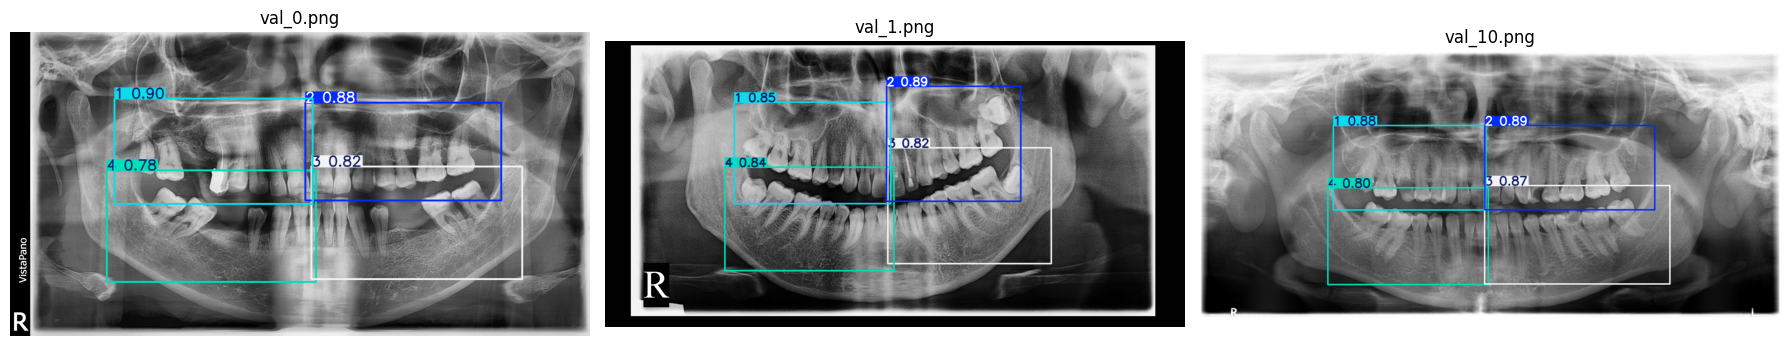

In [15]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# D:\.../quadrant_enumeration_disease/xrays yerine BASE_DIR'ın bir üst kırılımındaki validation_data aranıyor
# Projenizin ana dizini üzerinde ortak bir göreli yol kurgusu uyguluyoruz
if IN_COLAB:
    # Colab üzerinde drive yapısına uygun yol tanımlaması
    unlabeled_val_dir = Path("/content/drive/MyDrive/validation_data/validation_data/quadrant_enumeration_disease/xrays/xrays")
else:
    # Yerelde BASE_DIR'ın iki üst kırılımında validation_data arar
    base_dir = BASE_DIR if "BASE_DIR" in globals() else Path("./training_data/training_data/quadrant").resolve()
    unlabeled_val_dir = base_dir.parents[2] / "validation_data" / "validation_data" / "quadrant_enumeration_disease" / "xrays"

preds = best_model.predict(
    source=str(unlabeled_val_dir.resolve()) if unlabeled_val_dir.exists() else str(unlabeled_val_dir),
    conf=0.5,
    save=True,
    project="dentex_quadrant",
    name="unlabeled_val_preds"
)

# İlk 3 tahmin sonucunu notebook içinde görselleştir
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i in range(min(3, len(preds))):
    plotted = preds[i].plot()
    axes[i].imshow(cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB))
    axes[i].set_title(Path(preds[i].path).name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()